# Maschinelles Lernen (ML) - Übung 4
# Logistische Regression

In dieser Übung implementieren wir zunächst ein einzelnes Neuron "from scratch" für binäre Klassifikation, erst mit Sprungfunktion und dann mit Sigmoid-Aktivierung, und wenden anschließend `scikit-learn` auf einen realen Datensatz an. Den Abschluss bilden Klassifikationsmetriken (Confusion Matrix, Precision/Recall/F1, ROC).

Weitere Hintergründe (Herleitung, Formeln) finden Sie im PDF-Handout zu dieser Übung.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_curve, roc_auc_score,
)

np.random.seed(42)

**Aufgabe 1: Vom Perzeptron zum Sigmoid-Neuron**

*Teil A: Perzeptron (Neuron mit Sprungfunktion).* Das klassische Perzeptron wendet auf $z = \mathbf{w}^\top\mathbf{x}$ eine Sprungfunktion (Schwellwertoperation) an: $\hat y = 1$ falls $z \ge 0$, sonst $\hat y = 0$. Der Bias ist wie im Handout als `w[0]` eingebettet.

a) Der Datensatz in der folgenden Zelle (`make_blobs`, `n_samples=200`, `centers=2`, `n_features=2`, `random_state=42`, `cluster_std=1.5`) wird in dieser ganzen Aufgabe verwendet. Führen Sie die Zelle aus.

b) Implementieren Sie `step(z)` (gibt `1.0` für `z >= 0` und sonst `0.0` zurück) sowie `train_perceptron(X, y, lr, epochs)`: Erweitern Sie `X` einmalig zu `X_b` und initialisieren Sie `w` mit Nullen. In jeder Epoche berechnen Sie die Vorhersagen `y_hat = step(X_b @ w)`, speichern die Anzahl der falsch klassifizierten Punkte (`y_hat != y`) in der Liste `errors_history` und aktualisieren `w += lr * X_b.T @ (y - y_hat) / n`. Die Funktion soll `w` und `errors_history` zurückgeben.

In [4]:
X_blobs, y_blobs = make_blobs(n_samples=200, centers=np.array([[-1, -1], [9, 9]]), n_features=2, random_state=42, cluster_std=1.5)

In [ ]:
def step(z):
    ### Dein Code kommt hierhin:
    y = []
    for i in z:
        if i>=0:
            y.append(1.0)
        else:
            y.append(0.0)
    return y
    ##########################


def train_perceptron(X, y, lr=0.1, epochs=1000):
    n, d = X.shape
    X_b = np.c_[np.ones(n), X]
    w = np.zeros(d + 1)
    errors_history = []
    ### Dein Code kommt hierhin:
    for _ in range(epochs):
        y_hat = step(X_b @ w)
        errors_history.append(np.count_nonzero(y_hat != y))
        w += lr * X_b.T @ ( y - y_hat ) / n
    ##########################
    return w, errors_history

c) Trainieren Sie das Perzeptron und betrachten Sie Datenpunkte, Entscheidungsgrenze und die Anzahl der Fehler pro Epoche.

w (w[0] ist der eingebettete Bias): [-0.0695      0.04346669  0.03057191]
Fehler in den ersten 10 Epochen: [100, 10, 7, 5, 5, 5, 4, 2, 1, 0]
Fehler in der letzten Epoche: 0


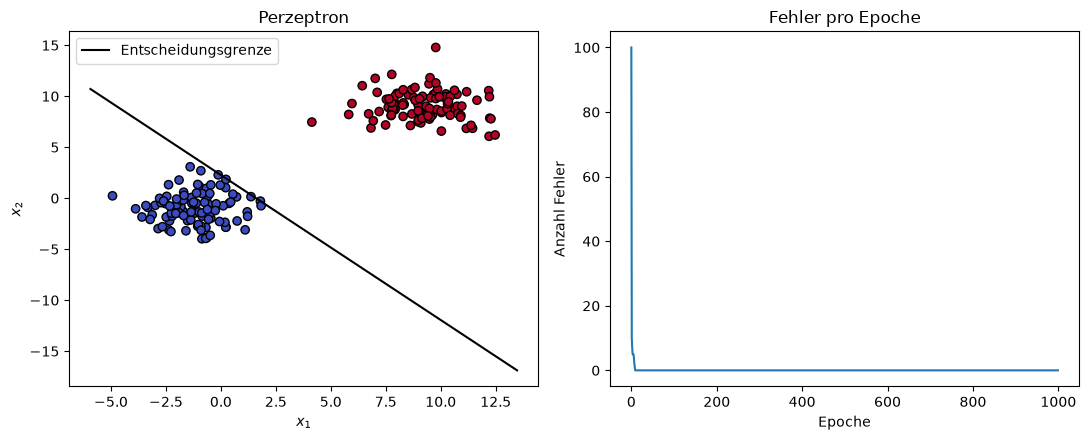

In [8]:
w_perc, errors_history = train_perceptron(X_blobs, y_blobs, lr=0.1, epochs=1000)
print("w (w[0] ist der eingebettete Bias):", w_perc)
print("Fehler in den ersten 10 Epochen:", [int(e) for e in errors_history[:10]])
print("Fehler in der letzten Epoche:", int(errors_history[-1]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ax = axes[0]
ax.scatter(X_blobs[:, 0], X_blobs[:, 1], c=y_blobs, cmap="coolwarm", edgecolor="k")
x1_range = np.linspace(X_blobs[:, 0].min() - 1, X_blobs[:, 0].max() + 1, 100)
ax.plot(x1_range, -(w_perc[1] * x1_range + w_perc[0]) / w_perc[2], "k-", label="Entscheidungsgrenze")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("Perzeptron")
ax.legend()

axes[1].plot(errors_history)
axes[1].set_xlabel("Epoche")
axes[1].set_ylabel("Anzahl Fehler")
axes[1].set_title("Fehler pro Epoche")

plt.tight_layout()
plt.show()

Sobald kein Punkt mehr falsch klassifiziert wird, ist $y - \hat y = 0$ für alle Punkte, und der Update-Schritt verändert `w` nicht mehr: Das Perzeptron hört auf zu lernen, auch wenn die Entscheidungsgrenze nur knapp an einzelnen Datenpunkten vorbeiläuft. Außerdem ist die Ableitung der Sprungfunktion fast überall null. Die Update-Regel des Perzeptrons ist deshalb kein Gradientenabstieg.

*Teil B: Sigmoid-Neuron.* Ersetzen wir die Sprungfunktion durch die Sigmoid-Funktion, wird die Ausgabe (und damit der Loss) differenzierbar in `w`.

a) Implementieren Sie die Sigmoid-Funktion `sigmoid(z)`.

b) Implementieren Sie den Vorwärtsdurchlauf `forward(X, w)`. Erweitern Sie `X` dabei zunächst intern um eine Spalte aus Einsen (Bias-Trick, vgl. Handout Gleichung (2)): `X_b = np.c_[np.ones(len(X)), X]`. Berechnen Sie anschließend `z = X_b @ w` und geben Sie `sigmoid(z)` zurück. Der Bias ist damit als `w[0]` Teil von `w`; eine separate Bias-Variable gibt es nicht mehr.

c) Implementieren Sie die binäre Kreuzentropie `bce_loss(y, y_hat)` gemäß Formel (4) im Handout. Klippen Sie `y_hat` mit `np.clip` auf ein kleines Intervall wie `[1e-12, 1 - 1e-12]`, um `log(0)` zu vermeiden.

d) Implementieren Sie `train_logreg(X, y, lr, epochs)`: Erweitern Sie `X` einmalig zu `X_b` (wie in b), initialisieren Sie `w` mit Nullen (Länge: Anzahl Merkmale plus 1 für den eingebetteten Bias), führen Sie dann `epochs` Schritte Gradientenabstieg gemäß Formel (5) im Handout durch und protokollieren Sie den Loss jeder Epoche in einer Liste `loss_history`. Die Funktion soll `w` und `loss_history` zurückgeben.

e) Trainieren Sie Ihr Sigmoid-Neuron auf dem Datensatz aus Teil A.

In [ ]:
def sigmoid(z):
    ### Dein Code kommt hierhin:
    return 1/(1+np.exp(-z))
    ##########################

In [66]:
def forward(X, w):
    ### Dein Code kommt hierhin:
    z = X @ w
    return sigmoid(z)
    ##########################

In [67]:
def bce_loss(y, y_hat, eps=1e-12):
    ### Dein Code kommt hierhin:
    y_hat_clipped = np.clip(y_hat, eps, 1-eps)
    return -np.mean(y * np.log(y_hat_clipped) + (1 - y) * np.log(1 - y_hat_clipped))
    ##########################

In [71]:
def train_logreg(X, y, lr=0.1, epochs=1000):
    n, d = X.shape
    X_b = np.c_[np.ones(n), X]
    w = np.zeros(d + 1)
    loss_history = []
    ### Dein Code kommt hierhin:
    for _ in range(epochs):
        y_hat = forward(X_b, w)
        loss = bce_loss(y, y_hat)
        loss_history.append(loss)
        w -= lr * X_b.T @ (y_hat - y) / n
    ##########################
    return w, loss_history

In [72]:
w, loss_history = train_logreg(X_blobs, y_blobs, lr=0.1, epochs=5000)
print("w (w[0] ist der eingebettete Bias):", w)
print("finaler Loss:", loss_history[-1])

w (w[0] ist der eingebettete Bias): [-4.84551167  1.02351809  0.64214467]
finaler Loss: 0.00237192327886533


f) Plotten Sie die Datenpunkte (eingefärbt nach Klasse) zusammen mit der gelernten Entscheidungsgrenze sowie den Verlauf des Trainings-Loss über die Epochen.

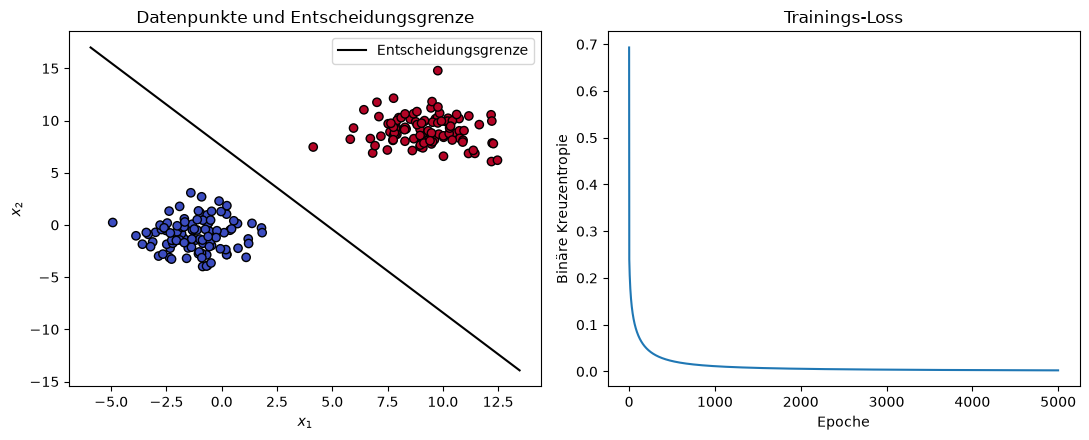

In [73]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ax = axes[0]
ax.scatter(X_blobs[:, 0], X_blobs[:, 1], c=y_blobs, cmap="coolwarm", edgecolor="k")
x1_range = np.linspace(X_blobs[:, 0].min() - 1, X_blobs[:, 0].max() + 1, 100)
x2_boundary = -(w[1] * x1_range + w[0]) / w[2]
ax.plot(x1_range, x2_boundary, "k-", label="Entscheidungsgrenze")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("Datenpunkte und Entscheidungsgrenze")
ax.legend()

axes[1].plot(loss_history)
axes[1].set_xlabel("Epoche")
axes[1].set_ylabel("Binäre Kreuzentropie")
axes[1].set_title("Trainings-Loss")

plt.tight_layout()
plt.show()

g) Zeichnen Sie die Entscheidungsgrenzen von Perzeptron und Sigmoid-Neuron in einen Plot und geben Sie für beide den Abstand des nächstgelegenen Datenpunkts zur Grenze aus. Vergleichen Sie die beiden Grenzen: Welche erscheint Ihnen plausibler, und warum lernt das Sigmoid-Neuron auch dann weiter, wenn kein Punkt mehr falsch klassifiziert wird?

Perzeptron: kleinster Abstand eines Datenpunkts zur Grenze = 0.0030
Sigmoid + BCE: kleinster Abstand eines Datenpunkts zur Grenze = 2.6404


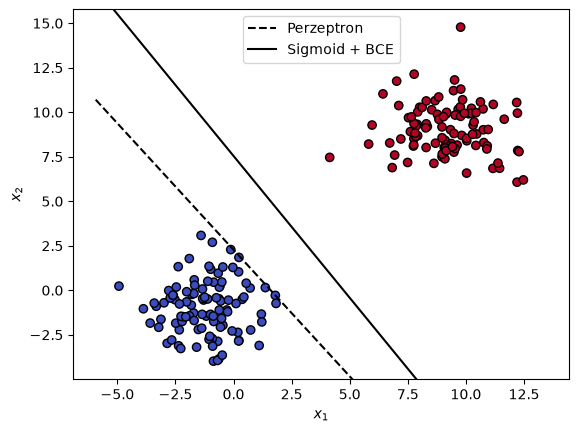

In [74]:
X_b_blobs = np.c_[np.ones(len(X_blobs)), X_blobs]

for name, w_modell in [("Perzeptron", w_perc), ("Sigmoid + BCE", w)]:
    abstand = np.abs(X_b_blobs @ w_modell) / np.linalg.norm(w_modell[1:])
    print(f"{name}: kleinster Abstand eines Datenpunkts zur Grenze = {abstand.min():.4f}")

plt.scatter(X_blobs[:, 0], X_blobs[:, 1], c=y_blobs, cmap="coolwarm", edgecolor="k")
x1_range = np.linspace(X_blobs[:, 0].min() - 1, X_blobs[:, 0].max() + 1, 100)
plt.plot(x1_range, -(w_perc[1] * x1_range + w_perc[0]) / w_perc[2], "k--", label="Perzeptron")
plt.plot(x1_range, -(w[1] * x1_range + w[0]) / w[2], "k-", label="Sigmoid + BCE")
plt.ylim(X_blobs[:, 1].min() - 1, X_blobs[:, 1].max() + 1)
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.legend()
plt.show()

**Aufgabe 2: Logistische Regression mit scikit-learn**

a) Laden Sie den Datensatz `load_breast_cancer` und betrachten Sie `X.shape` sowie die Klassenverteilung von `y`.

b) Teilen Sie die Daten mit `train_test_split` (`test_size=0.2`, `random_state=42`) in Trainings- und Testdaten auf. Skalieren Sie die Merkmale mit `StandardScaler`; passen Sie den Scaler dabei **ausschließlich** auf den Trainingsdaten an (`fit_transform`) und wenden Sie ihn auf die Testdaten nur an (`transform`).

c) Trainieren Sie ein `LogisticRegression`-Modell (`random_state=42`) auf den skalierten Trainingsdaten und geben Sie die Genauigkeit (`.score`) auf Trainings- und Testdaten aus.

In [75]:
data = load_breast_cancer()
X_bc, y_bc = data.data, data.target
print("X.shape:", X_bc.shape)
print("Klassenverteilung:", np.bincount(y_bc))

X.shape: (569, 30)
Klassenverteilung: [212 357]


In [76]:
### Dein Code kommt hierhin:
X_train, X_test, y_train, y_test = train_test_split(X_bc, y_bc, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
##########################

In [80]:
### Dein Code kommt hierhin:
logreg = LogisticRegression(random_state=42)
logreg.fit(X_train_scaled, y_train)
##########################

print("Trainingsgenauigkeit:", logreg.score(X_train_scaled, y_train))
print("Testgenauigkeit:     ", logreg.score(X_test_scaled, y_test))

Trainingsgenauigkeit: 0.9868131868131869
Testgenauigkeit:      0.9736842105263158


**Aufgabe 3: Klassifikationsmetriken**

a) Berechnen Sie die Confusion Matrix für Ihr Modell aus Aufgabe 2 auf den Testdaten (`confusion_matrix`) und visualisieren Sie sie mit `ConfusionMatrixDisplay`.

b) Lassen Sie sich Precision, Recall und $F_1$-Score je Klasse mit `classification_report` ausgeben.

c) Berechnen Sie die ROC-Kurve (`roc_curve`) und die AUC (`roc_auc_score`) und plotten Sie die ROC-Kurve zusammen mit der Diagonalen eines zufälligen Klassifikators. Beachten Sie: In `load_breast_cancer` ist Label 0 = `malignant` und Label 1 = `benign`; `predict_proba(...)[:, 1]` und `roc_curve` behandeln daher *gutartig* als positive Klasse.

d) **Diskussionsfrage:** Welcher Fehler (False Negative oder False Positive) ist bei diesem Datensatz schwerwiegender, und wie könnte man den Entscheidungsschwellwert entsprechend anpassen?

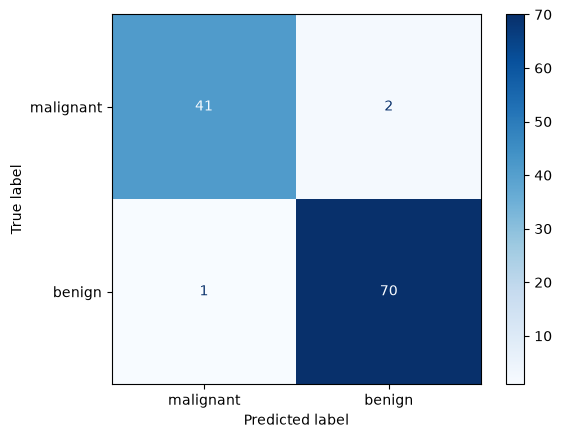

In [81]:
y_pred = logreg.predict(X_test_scaled)

### Dein Code kommt hierhin:
cm = confusion_matrix(y_test, y_pred)
##########################
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=data.target_names)
disp.plot(cmap="Blues")
plt.show()

In [85]:
### Dein Code kommt hierhin:
print(classification_report(y_test, y_pred))
##########################

              precision    recall  f1-score   support

           0       0.98      0.95      0.96        43
           1       0.97      0.99      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



AUC: 0.99737962659679


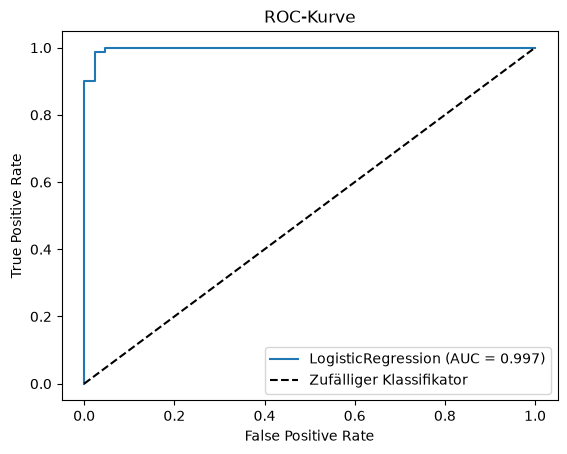

In [91]:
### Dein Code kommt hierhin:
y_scores = logreg.predict_proba(X_test_scaled)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_scores)
auc = roc_auc_score(y_test, y_scores)
##########################
print("AUC:", auc)

plt.plot(fpr, tpr, label=f"LogisticRegression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Zufälliger Klassifikator")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-Kurve")
plt.legend()
plt.show()

*Antwort:* False Negatives sind deutlich schlimmer als False Positives